In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [ ]:
from datasets import load_dataset

 Load datasets: - Load the dair-ai/emotion dataset from Hugging Face. https://huggingface.co/datasets/dair-ai/emotion

In [ ]:
emotion_datset=load_dataset("dair-ai/emotion")

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [ ]:
emotion_datset['test']

Dataset({
    features: ['text', 'label'],
    num_rows: 2000
})

In [ ]:
train_text = emotion_datset['train']['text']
train_label = emotion_datset['train']['label']

In [ ]:
test_text = emotion_datset['test']['text']
test_label = emotion_datset['test']['label']

In [ ]:
emotion_datset['train'].features

{'text': Value('string'),
 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}

In [ ]:
label_name = emotion_datset['train'].features['label'].names

In [ ]:
label_name

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [ ]:
train_label

Column([0, 0, 3, 2, 3, ...])

In [ ]:
for i in train_label :
  print(label_name[i])

Streaming output truncated to the last 5000 lines.
sadness
sadness
anger
fear
love
joy
anger
sadness
sadness
joy
fear
joy
fear
love
love
anger
anger
sadness
fear
sadness
sadness
surprise
love
joy
joy
love
sadness
joy
joy
fear
sadness
anger
anger
sadness
love
fear
fear
anger
anger
joy
sadness
sadness
joy
joy
fear
sadness
joy
love
fear
anger
sadness
joy
anger
surprise
fear
joy
joy
love
fear
sadness
joy
anger
fear
anger
sadness
sadness
sadness
anger
sadness
fear
joy
anger
anger
sadness
fear
joy
anger
fear
sadness
joy
fear
joy
love
anger
fear
fear
fear
fear
joy
anger
anger
sadness
joy
sadness
joy
sadness
sadness
joy
sadness
fear
fear
joy
sadness
joy
sadness
joy
fear
anger
sadness
joy
anger
joy
joy
sadness
joy
joy
anger
anger
joy
joy
joy
sadness
joy
joy
joy
anger
anger
joy
love
joy
love
joy
joy
joy
sadness
joy
sadness
surprise
sadness
anger
anger
anger
fear
fear
joy
fear
fear
joy
anger
joy
joy
joy
love
joy
fear
sadness
sadness
surprise
sadness
sadness
anger
joy
love
fear
joy
anger
joy
surpr

In [ ]:
df_train = pd.DataFrame({
    "text":train_text,
    "label":[label_name[i] for i in train_label]
}
    )
df_test = pd.DataFrame(
    {
        'text'  : test_text,
        'label' : [label_name[i] for i in test_label]
    }
)

In [ ]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [ ]:
df_train.isnull().sum()

,0
text,0
label,0


EDA


In [ ]:
count = df_train['label'].value_counts()

<Axes: xlabel='label', ylabel='count'>

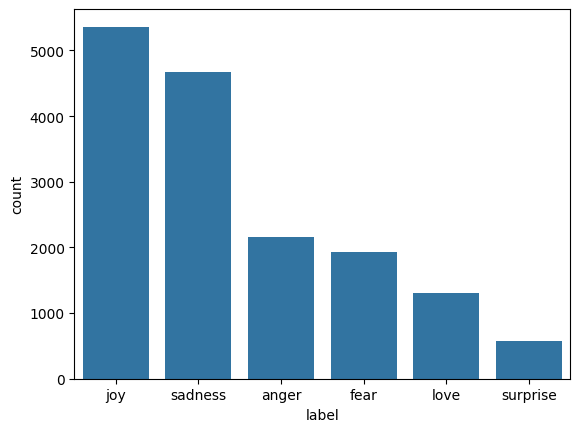

In [ ]:
sns.countplot(x='label',data=df_train , order=count.index)

Data Prepocessing - using NLP

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words=max_words, oov_token="<unk>")
tokenizer.fit_on_texts(df_train['text'])
train_sequ = tokenizer.texts_to_sequences(df_train['text'])
test_sequ = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequ = pad_sequences(train_sequ, maxlen=100, padding='post', truncating='post')
padded_test_sequ = pad_sequences(test_sequ, maxlen=100, padding='post', truncating='post')

train_label = np.array(train_label)
test_label = np.array(test_label)

num_classes = len(np.unique(train_label))


In [ ]:
train_sequ

[[2, 139, 3, 679],
 [2,
  40,
  101,
  60,
  8,
  15,
  494,
  5,
  15,
  3496,
  553,
  32,
  60,
  61,
  128,
  148,
  76,
  1480,
  4,
  22,
  1255],
 [17, 3060, 7, 1149, 5, 286, 2, 3, 495, 438],
 [2, 24, 165, 8, 665, 27, 6, 4158, 2, 59, 47, 9, 13, 22, 72, 30, 6, 3497],
 [2, 24, 8, 1065],
 [73, 48, 8, 7, 56, 521, 319, 328, 158, 161, 9, 20],
 [73,
  48,
  329,
  35,
  7401,
  35,
  196,
  7402,
  888,
  4,
  73,
  2475,
  1384,
  7,
  159,
  1885,
  19,
  2,
  117,
  3,
  14,
  15,
  455],
 [2, 3, 29, 439, 27, 78, 29, 7, 1686, 35, 29, 760, 29, 7, 193, 267, 374],
 [2,
  21,
  48,
  25,
  5260,
  16,
  215,
  2,
  3,
  9,
  5260,
  99,
  5261,
  135,
  4,
  132,
  7,
  1038,
  4159],
 [2, 3, 666, 94],
 [2, 3, 14, 2, 21, 5, 80, 6, 733, 2, 93, 544, 304, 84],
 [2,
  39,
  3,
  9,
  483,
  22,
  7,
  530,
  440,
  4,
  9,
  2,
  40,
  920,
  5,
  21,
  69,
  840,
  10,
  1886,
  3061],
 [2, 70, 13, 90, 6, 5262, 52, 10, 193, 5, 3, 610],
 [2, 3, 339, 456, 2, 93, 32, 4160],
 [2,
  21,
  4161,

In [ ]:
test_sequ

[[17, 8, 203, 715, 15, 17, 26, 46, 5595, 114, 58],
 [17, 1, 11, 243, 37, 2, 3, 469],
 [2,
  145,
  80,
  68,
  2971,
  60,
  18,
  37,
  2,
  104,
  43,
  165,
  67,
  68,
  5,
  3,
  14,
  2,
  93,
  406,
  25,
  68],
 [2,
  172,
  25,
  11,
  1,
  10,
  873,
  4,
  5366,
  1,
  736,
  11,
  1518,
  8,
  351,
  38,
  608,
  95,
  34,
  2,
  1973],
 [2, 20, 8, 7, 56, 654, 34, 2, 127, 23, 71],
 [2, 131, 421, 106, 7, 1515, 1439, 153, 2, 39, 26, 3, 498],
 [2, 144, 974, 34, 33, 6, 228, 10, 7, 5667, 388],
 [2,
  962,
  161,
  2,
  9809,
  5,
  7,
  635,
  25,
  7,
  782,
  76,
  20,
  12,
  160,
  576,
  2771,
  4,
  1,
  865,
  6,
  1824,
  2,
  121,
  21,
  48,
  8,
  16,
  180,
  294,
  106,
  6,
  3471,
  1658,
  33,
  6,
  1858,
  10,
  3559],
 [2, 14, 5, 21, 6, 224, 1, 8, 29, 7, 1600, 723, 5, 113, 54, 59, 518, 292],
 [2,
  1,
  2,
  3,
  796,
  288,
  4,
  2369,
  1,
  108,
  2,
  338,
  24,
  19,
  125,
  129,
  79,
  118,
  48,
  7,
  202,
  4,
  17,
  27,
  29,
  1047,
  29,
  7,
 

In [ ]:
padded_train_sequ

array([[   2,  139,    3, ...,    0,    0,    0],
       [   2,   40,  101, ...,    0,    0,    0],
       [  17, 3060,    7, ...,    0,    0,    0],
       ...,
       [   2,    3,  327, ...,    0,    0,    0],
       [   2,    3,   14, ...,    0,    0,    0],
       [   2,   47,    7, ...,    0,    0,    0]], dtype=int32)

In [ ]:
num_classes

6

In [ ]:
print(f"vocabulary size: {len(tokenizer.word_index)}")
print(f"Max sentence Lenght : {padded_train_sequ.shape[1]}")

vocabulary size: 15213
Max sentence Lenght : 100


In [ ]:
from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight(
     class_weight='balanced',
    classes=np.unique(train_label),
    y=train_label
)
class_weights = {i : class_weights[i] for i in range(num_classes)}
class_weights

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [ ]:
dict(enumerate(class_weights))

{0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5}

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

early_stopping =EarlyStopping(monitor='val_loss',
                              patience=3,
                              restore_best_weights=True)



In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout

model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=100),
    SimpleRNN(units=128 ,return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') # output Layer
])

rnn_model=model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
model.fit(
    padded_train_sequ,
    train_label,
    validation_data=(padded_test_sequ, test_label),
    epochs=20,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping]
)
rnn_loss , rnn_accuracy = model.evaluate(padded_test_sequ, test_label)
print(f"RNN Loss : {rnn_loss}")
print(f"RNN Accuracy : {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 51ms/step - accuracy: 0.1580 - loss: 2.0426 - val_accuracy: 0.1045 - val_loss: 1.7858
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.1458 - loss: 1.8813 - val_accuracy: 0.1075 - val_loss: 1.7804
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 54ms/step - accuracy: 0.1324 - loss: 1.8289 - val_accuracy: 0.2305 - val_loss: 1.8010
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 52ms/step - accuracy: 0.1399 - loss: 1.8070 - val_accuracy: 0.0405 - val_loss: 1.8208
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 35s 69ms/step - accuracy: 0.1337 - loss: 1.8031 - val_accuracy: 0.1155 - val_loss: 1.7754
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 35s 57ms/step - accuracy: 0.1318 - loss: 1.8025 - val_accuracy: 0.0825 - val_loss: 1.7762
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 39s 53ms/step - accuracy: 0.1460 - loss: 1.7996 - val_accuracy: 0.3250 - val_loss: 1.7645
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 44s 59ms/step - accuracy: 0.1376 - loss: 1.8008 - 

In [ ]:
lstm_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=100),
    LSTM(units=128 , return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') # output Layer
])

lstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequ,
    train_label,
    validation_data=(padded_test_sequ, test_label),
    epochs=20,
    batch_size=32,
    class_weight = class_weights,
    callbacks=[early_stopping]
)
lstm_loss , lstm_accuracy = model.evaluate(padded_test_sequ, test_label)
print(f"LSTM Loss : {lstm_loss}")
print(f"LSTM Accuracy : {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 97s 190ms/step - accuracy: 0.1331 - loss: 1.7944 - val_accuracy: 0.1375 - val_loss: 1.7724
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 94s 187ms/step - accuracy: 0.1623 - loss: 1.7940 - val_accuracy: 0.0330 - val_loss: 1.7987
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 162s 227ms/step - accuracy: 0.1307 - loss: 1.7939 - val_accuracy: 0.2905 - val_loss: 1.7770
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.3190 - loss: 1.7429
LSTM Loss : 1.7428839206695557
LSTM Accuracy : 0.3190000057220459


In [ ]:
from tensorflow.keras.layers import GRU
gru_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=100),
    GRU(units=128 , return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') # output Layer
])

gru_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

gru_model.fit(
    padded_train_sequ,
    train_label,
    validation_data=(padded_test_sequ, test_label),
    epochs=20,
    batch_size=32,
    class_weight = class_weights,
    callbacks=[early_stopping]
)
gru_loss , gru_accuracy = model.evaluate(padded_test_sequ, test_label)
print(f"gru Loss : {gru_loss}")
print(f"gru Accuracy : {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 73s 139ms/step - accuracy: 0.1584 - loss: 1.7966 - val_accuracy: 0.2905 - val_loss: 1.7495
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 80s 135ms/step - accuracy: 0.1557 - loss: 1.7957 - val_accuracy: 0.0795 - val_loss: 1.8038
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 72s 144ms/step - accuracy: 0.1461 - loss: 1.7953 - val_accuracy: 0.0795 - val_loss: 1.7930
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.3190 - loss: 1.7429
gru Loss : 1.7428839206695557
gru Accuracy : 0.3190000057220459


In [ ]:
result_df =  pd.DataFrame({
    "Model" : ["RNN" , "LSTM" , "GRU"],
    "Test Loss" : [rnn_loss , lstm_loss , gru_loss],
    "Test Accuracy" : [rnn_accuracy , lstm_accuracy , gru_accuracy]
}).sort_values(by="Test Accuracy" , ascending=False)
result_df


,Model,Test Loss,Test Accuracy
0,RNN,1.742884,0.319
1,LSTM,1.742884,0.319
2,GRU,1.742884,0.319


In [ ]:
from tensorflow.keras.layers import Bidirectional
BRIGRU = Sequential([
    Embedding(input_dim=max_words, output_dim=300, input_length=100),
    Bidirectional(GRU(units=128 , return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') # output Layer

])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
BRIGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
BRIGRU.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
BRIGRU.fit(
    padded_train_sequ,
    train_label,
    validation_data=(padded_test_sequ, test_label),
    epochs=20,
    batch_size=32,
    class_weight = class_weights,
    callbacks =[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 188s 368ms/step - accuracy: 0.5422 - loss: 1.0457 - val_accuracy: 0.8795 - val_loss: 0.3668
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 183s 366ms/step - accuracy: 0.9183 - loss: 0.2392 - val_accuracy: 0.9255 - val_loss: 0.1838
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 185s 369ms/step - accuracy: 0.9451 - loss: 0.1513 - val_accuracy: 0.9200 - val_loss: 0.2452
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 207s 380ms/step - accuracy: 0.9606 - loss: 0.1059 - val_accuracy: 0.9190 - val_loss: 0.2379
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 184s 368ms/step - accuracy: 0.9654 - loss: 0.0981 - val_accuracy: 0.9230 - val_loss: 0.2572


In [ ]:
BRIGRU_loss , BRIGRU_accuracy = BRIGRU.evaluate(padded_test_sequ, test_label)
print(f"BRIGRU Loss : {BRIGRU_loss}")
print(f"BRIGRU Accuracy : {BRIGRU_accuracy}")


63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - accuracy: 0.9255 - loss: 0.1838
BRIGRU Loss : 0.18380151689052582
BRIGRU Accuracy : 0.9254999756813049


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Use .predict() instead of .prediction()
BRIGRU_prediction = BRIGRU.predict(padded_test_sequ)
BRIGRU_prediction = np.argmax(BRIGRU_prediction, axis=1)

63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 263ms/step


<Axes: >

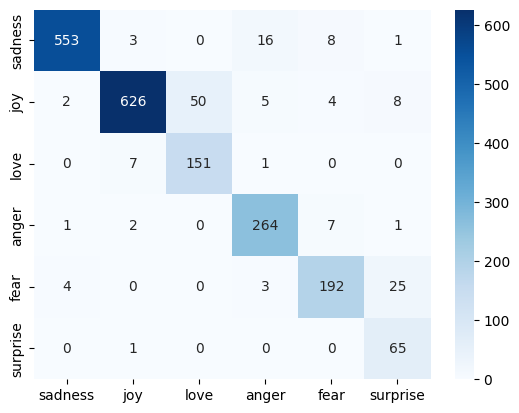

In [ ]:
sns.heatmap(confusion_matrix(test_label, BRIGRU_prediction), annot=True, fmt='g' , cmap='Blues',xticklabels=label_name , yticklabels=label_name)

In [ ]:
sample_text= [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequencess = tokenizer.texts_to_sequences(sample_text)
sample_sequencess = pad_sequences(sample_sequencess, maxlen=100, padding='post', truncating='post')

sample_prediction = np.argmax(BRIGRU.predict(sample_sequencess), axis=1)

for i in range(len(sample_text)):
    print(f"Text: {sample_text[i]}")
    print(f"Predicted Label: {label_name[sample_prediction[i]]}\n")
#

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Label: joy

Text: I feel so alone and hopeless today.
Predicted Label: sadness

Text: I am furious that they cancelled the trip at the last minute.
Predicted Label: anger

Text: I feel terrified when walking down dark alleyways alone.
Predicted Label: fear

Text: I was shocked and completely surprised by the unexpected gift!
Predicted Label: surprise



In [ ]:
import os
import pickle

model_dir = 'Artifact'
os.makedirs(model_dir, exist_ok=True)

# Save the Keras model
BRIGRU.save(os.path.join(model_dir, 'brigru_model.keras'))

# Correctly open a file to pickle the tokenizer
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
    pickle.dump(tokenizer, file)